# 좋은 도구 이름과 설명

**이 노트북에서 할 일**

1. 주문 한 건 찾기와 금액 합계 세기의 몸통 함수 둘을 만듭니다.
2. 같은 몸통 함수에 설명만 다른 도구 두 판을 붙이고 명세를 견줍니다.
3. 이 절에서 정한 기준 넷으로 두 판의 이름과 설명을 코드로 봅니다.
4. 명세 글자 수를 세고, 이름만 바꾼 도구를 같은 기준으로 봅니다.

**준비물** — 이 절은 모델을 부르지 않습니다.
모델 요청은 0번이라 API 키가 필요 없고, 드는 비용도 없습니다.
도구 명세는 파이썬 안에서 만들어져서 모델 없이 볼 수 있기 때문입니다.
모델이 이 명세를 읽고 도구를 고르는 장면은 04절에서 봅니다.

읽는 파일은 실습 폴더의 `data/orders.csv` 하나이고, 새로 쓰는 파일은 없습니다.
Ch 4 함수 `fetch_orders`는 같은 폴더의 도구 파일 `order_tools.py`에서 가져옵니다.
교재 출력을 만든 실행에서는 노트북 전체가 3초 안에 끝났습니다.

**기준 버전** — 첫 셀에서 패키지 셋을 설치합니다.
판은 langchain 1.4.0, langchain-core 1.6.2, pandas 3.0.5입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~5절을 읽습니다.
몸통 함수를 만들고, 두 판의 도구를 기준으로 견주는 자리입니다.
6~7절은 명세 글자 수를 세고 이름만 바꿔 보는 자리입니다.
이 부분은 실습 시간에 실행합니다.

실습 폴더 `labs/part5/ch19-model-tools`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 맨 위 파란 상자 몸통 함수 find_order csv_path order_id에서 회색 상자 둘 @tool 짧은 판 get_order_by_id와 @tool 자세한 판 get_order_by_id로 갈라지고, 왼쪽 아래 노란 상자에 설명 한 문장 주문 정보를 봅니다, 오른쪽 아래 노란 상자에 설명 네 문장 하는 일 언제 쓰는지 인자 order_id 내놓는 값이 있으며, 맨 아래 회색 상자에 두 판 공통 이름 같음 True 입력 형식 같음 True O103 부른 결과 같음 True가 적힌 그림](attachment:03-1-같은-몸통에-두-가지-설명.png)

위에서 아래로 읽습니다. 맨 위 파란 상자는 2절에서 적은 몸통 함수입니다.
회색 상자 둘은 `@tool` 줄이 같은 이름으로 감싼 두 판의 도구입니다.
노란 상자 둘은 3절과 4절이 출력한 두 판의 설명입니다.
맨 아래 회색 상자는 4절 출력으로 확인한 두 판의 공통점입니다.
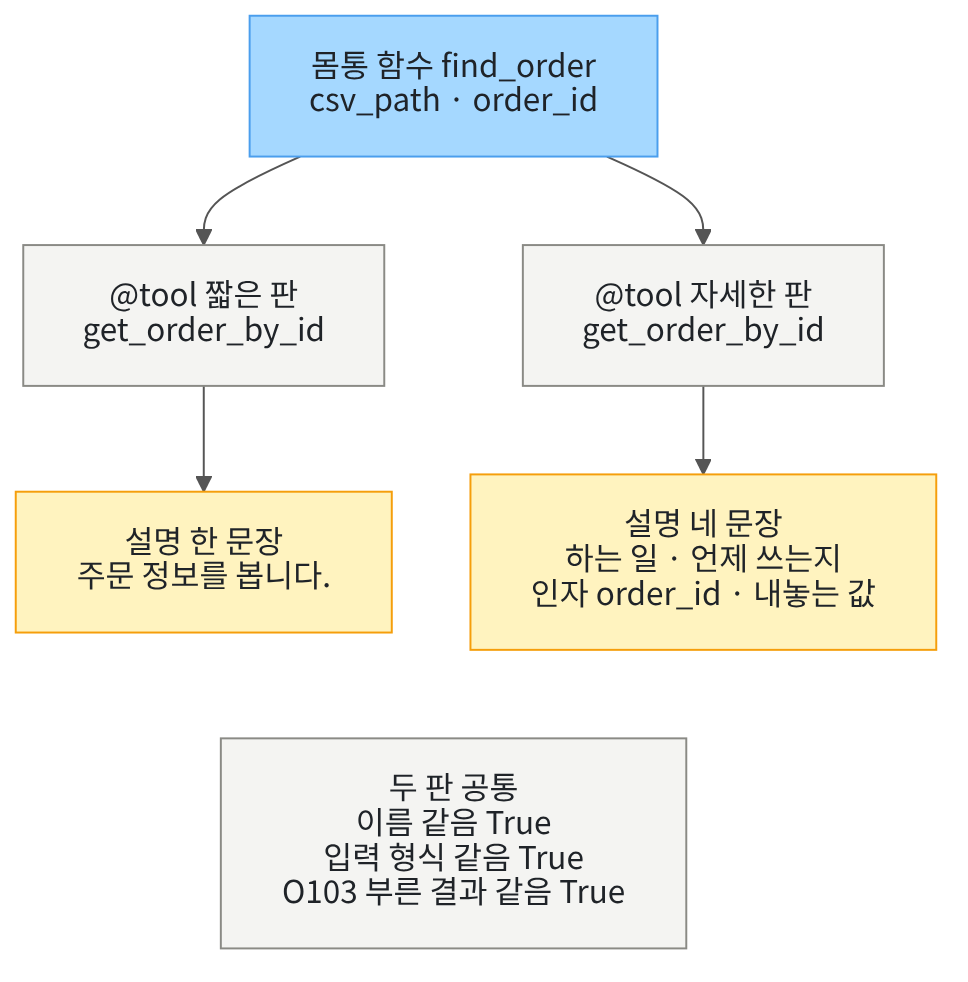

## 1. 준비

이 절은 모델이 읽을 도구 이름과 도구 설명을 어떻게 적을지 봅니다.
02절에서 본 것처럼 설명 글은 값을 막는 규칙이 아니고, 모델이 읽는 안내 글입니다.
그래서 이 절은 모델을 부르지 않고, 모델이 읽게 될 명세 글 자체를 견줍니다.
견주는 기준은 공식 문서의 권고를 바탕으로 이 절에서 정합니다.

첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-core==1.6.2" "pandas==3.0.5"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("pandas:", version("pandas"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
pandas: 3.0.5


**결과 읽기** — 출력 줄 `langchain: 1.4.0`·`langchain-core: 1.6.2`·`pandas: 3.0.5`가 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-24에 이 판으로 실행한 결과입니다.

앞에서 배운 함수는 `order_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

다음 셀은 이 절에서 쓸 이름 다섯을 가져옵니다.
모듈 `json`은 6절에서 도구 명세를 JSON 글로 바꿀 때 씁니다.
함수 `tool`과 `convert_to_openai_tool`은 01절에서 쓴 이름입니다.

In [2]:
# CSV 위치를 찾을 os, 명세를 글로 바꿀 json, 도구를 만드는 이름들, Ch 4 함수를 가져옵니다
import json
import os

from langchain.tools import tool
from langchain_core.utils.function_calling import convert_to_openai_tool

from order_tools import fetch_orders

print("가져온 이름:", "json", "os", "tool", "convert_to_openai_tool", "fetch_orders")

가져온 이름: json os tool convert_to_openai_tool fetch_orders


**결과 읽기** — 출력 줄에 가져온 이름 다섯이 보입니다.
함수 `fetch_orders`는 01절처럼 도구 파일에서 가져왔습니다.

다음 셀은 01절과 같은 방법으로 주문 CSV가 있는 프로젝트 맨 위 폴더를 찾습니다.
후보 세 곳을 차례로 보고, 파일이 있는 첫 자리에서 `break`로 멈춥니다.

In [3]:
# 노트북을 어느 폴더에서 열어도 주문 CSV를 찾게 후보 세 곳을 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part5/ch19-model-tools/data/orders.csv"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."
# CSV 파일 위치는 노트북이 정해 두는 값입니다(모델이 고를 값이 아님)
csv_path = root_path + "/labs/part5/ch19-model-tools/data/orders.csv"

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위: .`은 교재 출력을 프로젝트 맨 위에서 실행했다는 뜻입니다.
교재 출력은 실행 도구에 도구 파일 폴더를 따로 알려 준 실행이라 `.`이 찍혔습니다.
노트북을 `notebooks/` 폴더에서 열면 이 줄에 `../../../..`가 찍힙니다.
셀 안의 안내 글은 실습 폴더 맨 위도 적었지만, 도구 파일을 가져오려면 `notebooks/` 폴더에서 열어야 합니다.
변수 `csv_path`에 CSV 파일 위치를 담았습니다.

## 2. 몸통 함수 둘 만들기

01절 도구의 몸통은 Ch 4 함수를 한 번 부르는 한 줄이었습니다.
이 절은 주문 한 건 찾기와 금액 합계 세기를 더해 도구를 셋으로 늘립니다.
도구로 감싸기 전에 실제 일을 하는 평범한 함수를 이 절에서는 몸통 함수라고 부릅니다.
식당으로 치면 주방의 요리법이고, 손님은 이 코드를 보지 않습니다.

다음 셀은 주문 번호 하나로 주문 한 줄을 찾는 몸통 함수 `find_order`를 만듭니다.
모든 주문을 차례로 보다가, 번호가 같은 줄을 만나면 `break`로 멈춥니다.
끝까지 없으면 처음에 담아 둔 `None`을 그대로 내놓습니다.

In [4]:
# 주문 번호 하나로 주문 한 줄을 찾는 몸통 함수입니다(없으면 None을 내놓습니다)
def find_order(csv_path, order_id):
    found = None
    # 모든 주문을 읽고, 번호가 같은 줄을 만나면 담고 멈춥니다
    for row in fetch_orders(csv_path):
        if row["order_id"] == order_id:
            found = row
            break
    return found

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `find_order`는 CSV 파일 위치와 주문 번호를 인자로 받습니다.
CSV 파일 위치도 인자로 받아서, 노트북에서 만든 이름을 함수 안에서 바로 읽지 않습니다.

다음 셀은 있는 번호 `O103`과 CSV에 없는 번호 `O999`로 한 번씩 부릅니다.

In [5]:
# 있는 주문 번호 O103과 없는 번호 O999로 한 번씩 찾습니다
print("O103:", find_order(csv_path, "O103"))
print("O999:", find_order(csv_path, "O999"))

O103: {'order_id': 'O103', 'customer_id': 'C001', 'status': 'paid', 'amount': 27000}
O999: None


**결과 읽기** — 출력 줄 `O103:` 뒤에 칸 넷이 든 딕셔너리 한 줄이 있습니다.
금액 칸은 `'amount': 27000`이고, 상태 칸은 `'paid'`입니다.
출력 줄 `O999: None`은 그 번호의 주문이 CSV에 없다는 뜻입니다.

다음 셀은 주문 상태 하나로 주문 수와 금액 합계를 세는 몸통 함수 `sum_orders`를 만듭니다.
합계는 `total = total + row["amount"]`처럼 금액을 한 줄씩 더해 만듭니다.

In [6]:
# 주문 상태 하나로 그 상태의 주문 수와 금액 합계를 세는 몸통 함수입니다
def sum_orders(csv_path, status):
    rows = fetch_orders(csv_path, status=status)
    total = 0
    # 줄마다 금액을 더해 합계를 만듭니다
    for row in rows:
        total = total + row["amount"]
    return {"status": status, "count": len(rows), "total": total}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `sum_orders`는 상태·주문 수·합계 세 칸을 딕셔너리로 내놓습니다.
주문 수는 Ch 4 함수가 내놓은 목록의 길이 `len(rows)`입니다.

다음 셀은 결제된(paid) 주문의 수와 금액 합계를 셉니다.

In [7]:
# 결제된(paid) 주문의 수와 금액 합계를 셉니다
paid_summary = sum_orders(csv_path, "paid")
print("paid 합계:", paid_summary)

paid 합계: {'status': 'paid', 'count': 2, 'total': 59000}


**결과 읽기** — 출력 줄 `paid 합계: {'status': 'paid', 'count': 2, 'total': 59000}`에서 주문 수는 2입니다.
합계 `59000`은 결제된 두 주문의 금액 32000과 27000을 더한 값입니다.
두 몸통 함수는 이 절에서 처음 적었고, 같은 본문을 도구 파일에도 옮겨 두었습니다.
04절부터는 두 함수를 도구 파일에서 가져옵니다.

## 3. 짧은 판 도구 셋

이제 세 가지 일을 도구로 감쌉니다.
도구 이름은 셋 모두 하는 일을 뜻하는 영어 동사로 시작하게 지었습니다.
목록 찾기는 `list_orders_by_status`, 한 건 찾기는 `get_order_by_id`, 합계는 `sum_amounts_by_status`입니다.
이 절은 같은 이름에 설명만 다른 두 판을 만들어 견줍니다.

먼저 설명을 짧은 한 문장만 적은 판입니다.
다음 셀은 01절처럼 Ch 4 함수를 부르는 목록 도구입니다.

In [8]:
# 짧은 판: 주문 목록 도구에 설명을 짧은 한 문장만 적습니다
@tool
def list_orders_by_status(status: str):
    """주문을 찾습니다."""
    return fetch_orders(csv_path, status=status)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 이름과 몸통 줄은 01절 도구와 같고, 독스트링만 한 문장 「주문을 찾습니다.」로 짧습니다.

다음 두 셀도 같은 모양으로 한 건 도구와 합계 도구를 만듭니다.
몸통은 2절의 몸통 함수를 한 번 부르는 한 줄입니다.

In [9]:
# 짧은 판: 주문 한 건 도구에 설명을 짧은 한 문장만 적습니다
@tool
def get_order_by_id(order_id: str):
    """주문 정보를 봅니다."""
    return find_order(csv_path, order_id)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
몸통 줄은 몸통 함수 `find_order`에 CSV 파일 위치와 주문 번호를 넘깁니다.
모델이 채울 인자는 `order_id` 하나이고, CSV 파일 위치는 노트북이 정합니다.

다음 셀은 금액 합계 도구입니다.

In [10]:
# 짧은 판: 금액 합계 도구에 설명을 짧은 한 문장만 적습니다
@tool
def sum_amounts_by_status(status: str):
    """주문 금액을 봅니다."""
    return sum_orders(csv_path, status)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 도구도 모델이 채울 인자는 `status` 하나입니다.

다음 셀은 짧은 판 도구 셋을 목록 `short_tools`에 담고 이름과 설명을 봅니다.

In [11]:
# 짧은 판 도구 셋을 목록에 담고 도구마다 이름과 설명을 봅니다
short_tools = [list_orders_by_status, get_order_by_id, sum_amounts_by_status]
for one_tool in short_tools:
    print(one_tool.name, "|", one_tool.description)

list_orders_by_status | 주문을 찾습니다.
get_order_by_id | 주문 정보를 봅니다.
sum_amounts_by_status | 주문 금액을 봅니다.


**결과 읽기** — 출력 세 줄에서 세로 줄 앞이 도구 이름, 뒤가 도구 설명입니다.
설명은 `주문을 찾습니다.`·`주문 정보를 봅니다.`·`주문 금액을 봅니다.`로 모두 한 문장입니다.
세 설명 모두 목록인지 한 건인지 합계인지를 가르지 않습니다.
어떤 질문에 쓰는지, 인자에 무엇을 넣는지, 무엇을 내놓는지도 없습니다.

## 4. 자세한 판 도구 셋

이번에는 같은 이름으로 도구를 다시 만들고, 설명을 네 문장으로 적습니다.
네 문장은 하는 일·언제 쓰는지·인자 뜻·내놓는 값입니다.
순서는 OpenAI·Anthropic·LangChain 문서의 도구 설명 권고를 모아 이 절에서 정했습니다.
같은 이름에 새 도구가 담겨도, 3절 목록 `short_tools`에 담은 짧은 판 도구는 그대로 남습니다.

다음 셀은 목록 도구의 자세한 판입니다.

In [12]:
# 자세한 판: 같은 이름의 목록 도구에 하는 일·사용 조건·인자·내놓는 값을 네 문장으로 적습니다
@tool
def list_orders_by_status(status: str):
    """주문 상태로 주문 목록을 찾습니다. 한 상태의 주문을 여러 건 볼 때 씁니다. 인자 status는 paid, pending, cancelled 가운데 하나입니다. 그 상태의 주문 줄을 딕셔너리 목록으로 내놓습니다."""
    return fetch_orders(csv_path, status=status)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이름 `list_orders_by_status`에는 이제 자세한 판 도구가 담겼습니다.
몸통 줄은 3절 짧은 판과 같고, 독스트링만 네 문장으로 바뀌었습니다.
독스트링을 여러 줄로 나눠 적으면 둘째 줄부터 줄 앞 빈칸까지 설명에 들어갑니다.
그래서 네 문장을 한 줄에 적었습니다.

다음 두 셀도 한 건 도구와 합계 도구를 같은 이름으로 다시 만듭니다.

In [13]:
# 자세한 판: 같은 이름의 한 건 도구에 하는 일·사용 조건·인자·내놓는 값을 네 문장으로 적습니다
@tool
def get_order_by_id(order_id: str):
    """주문 번호로 주문 한 건을 찾습니다. 질문에 O103 같은 주문 번호가 있을 때 씁니다. 인자 order_id는 찾을 주문 번호입니다. 그 주문 한 줄을 딕셔너리로 내놓고, 없으면 None을 내놓습니다."""
    return find_order(csv_path, order_id)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
설명 둘째 문장이 이 도구를 언제 쓰는지 적습니다.
질문에 주문 번호가 있으면 이 도구를 쓰라는 안내입니다.

다음 셀은 합계 도구의 자세한 판입니다.

In [14]:
# 자세한 판: 같은 이름의 합계 도구에 하는 일·사용 조건·인자·내놓는 값을 네 문장으로 적습니다
@tool
def sum_amounts_by_status(status: str):
    """주문 상태로 주문 수와 금액 합계를 셉니다. 주문 목록 대신 개수나 합계를 물을 때 씁니다. 인자 status는 paid, pending, cancelled 가운데 하나입니다. 상태·주문 수·합계를 딕셔너리로 내놓습니다."""
    return sum_orders(csv_path, status)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
합계 도구의 설명은 주문 목록 대신 개수나 합계를 물을 때 쓴다고 적습니다.
목록 도구와 같은 인자 `status`를 받지만, 내놓는 값이 다릅니다.

다음 셀은 자세한 판 도구 셋을 목록 `detailed_tools`에 담습니다.
그리고 짧은 판과 이름·입력 형식이 같은지 도구마다 봅니다.

In [15]:
# 자세한 판 도구 셋을 목록에 담고, 짧은 판과 이름·입력 형식이 같은지 도구마다 봅니다
detailed_tools = [list_orders_by_status, get_order_by_id, sum_amounts_by_status]
for position in range(len(detailed_tools)):
    short_tool = short_tools[position]
    detailed_tool = detailed_tools[position]
    same_name = short_tool.name == detailed_tool.name
    same_args = short_tool.args == detailed_tool.args
    print(detailed_tool.name, "| 이름 같음:", same_name, "| 입력 형식 같음:", same_args)

list_orders_by_status | 이름 같음: True | 입력 형식 같음: True
get_order_by_id | 이름 같음: True | 입력 형식 같음: True
sum_amounts_by_status | 이름 같음: True | 입력 형식 같음: True


**결과 읽기** — 출력 세 줄 모두 `이름 같음: True`와 `입력 형식 같음: True`입니다.
두 판은 도구 이름과 입력 형식이 같고, 도구 설명만 다릅니다.
몸통 줄도 두 판이 같아서, 이 절의 두 판은 설명 하나만 바꾼 비교입니다.

다음 셀은 자세한 판 도구마다 설명 글을 출력합니다.

In [16]:
# 자세한 판 도구마다 설명 글을 봅니다(짧은 판 설명은 3절에서 출력했습니다)
for one_tool in detailed_tools:
    print("도구", one_tool.name, "설명:")
    print(one_tool.description)

도구 list_orders_by_status 설명:
주문 상태로 주문 목록을 찾습니다. 한 상태의 주문을 여러 건 볼 때 씁니다. 인자 status는 paid, pending, cancelled 가운데 하나입니다. 그 상태의 주문 줄을 딕셔너리 목록으로 내놓습니다.
도구 get_order_by_id 설명:
주문 번호로 주문 한 건을 찾습니다. 질문에 O103 같은 주문 번호가 있을 때 씁니다. 인자 order_id는 찾을 주문 번호입니다. 그 주문 한 줄을 딕셔너리로 내놓고, 없으면 None을 내놓습니다.
도구 sum_amounts_by_status 설명:
주문 상태로 주문 수와 금액 합계를 셉니다. 주문 목록 대신 개수나 합계를 물을 때 씁니다. 인자 status는 paid, pending, cancelled 가운데 하나입니다. 상태·주문 수·합계를 딕셔너리로 내놓습니다.


**결과 읽기** — 라벨 줄 `도구 get_order_by_id 설명:` 아래 설명은 네 문장입니다.
첫 문장 `주문 번호로 주문 한 건을 찾습니다.`가 하는 일입니다.
둘째 문장은 언제 쓰는지, 셋째 문장은 인자 `order_id`의 뜻입니다.
넷째 문장은 내놓는 값이고, 주문이 없을 때 `None`을 내놓는다는 것까지 적었습니다.

설명을 바꾸면 도구가 하는 일도 바뀔까요?
다음 셀은 두 판의 한 건 도구를 같은 인자 딕셔너리로 불러 결과를 견줍니다.
목록의 둘째 자리 `[1]`에 한 건 도구가 있습니다.

In [17]:
# 두 판의 주문 한 건 도구를 같은 인자 딕셔너리로 불러 결과를 견줍니다
short_answer = short_tools[1].invoke({"order_id": "O103"})
detailed_answer = detailed_tools[1].invoke({"order_id": "O103"})
print("짧은 판:", short_answer)
print("자세한 판:", detailed_answer)
print("두 결과가 같은가:", short_answer == detailed_answer)
# 같은 몸통 함수가 CSV에서 찾는 값이라 assert로 확인합니다
assert short_answer == detailed_answer

짧은 판: {'order_id': 'O103', 'customer_id': 'C001', 'status': 'paid', 'amount': 27000}
자세한 판: {'order_id': 'O103', 'customer_id': 'C001', 'status': 'paid', 'amount': 27000}
두 결과가 같은가: True


**결과 읽기** — 두 판 모두 주문 `O103` 한 줄을 내놓았고, 출력 줄 `두 결과가 같은가: True`로 같습니다.
마지막 줄의 `assert`도 통과했습니다.
설명은 모델이 읽는 글이라, 도구를 부른 결과는 바꾸지 않습니다.
설명이 바꿀 수 있는 것은 모델이 이 도구를 고를지 말지이고, 그것은 04절에서 봅니다.

## 5. 이 절에서 정한 기준 넷

두 판을 눈으로만 보면 「자세한 판이 낫다」는 느낌만 남습니다.
그래서 이 절은 코드로 셀 수 있는 기준 넷을 정합니다.
이름이 동사로 시작하는지, 설명에 인자 이름이 있는지 봅니다.
설명에 「때 씁니다」와 「내놓습니다」가 있는지도 봅니다.

다음 셀은 이 기준을 코드로 셀 때 쓸 표 둘을 만듭니다.

In [18]:
# 이 절에서 정한 기준 표: 설명에서 찾을 낱말과, 이름의 첫 낱말로 볼 동사
check_words = {"언제 쓰는지": "때 씁니다", "내놓는 값": "내놓습니다"}
verbs = ["list", "get", "find", "search", "sum", "count"]
print("설명에서 찾을 낱말:", check_words)
print("이름 첫 낱말로 볼 동사:", verbs)

설명에서 찾을 낱말: {'언제 쓰는지': '때 씁니다', '내놓는 값': '내놓습니다'}
이름 첫 낱말로 볼 동사: ['list', 'get', 'find', 'search', 'sum', 'count']


**결과 읽기** — 라벨 줄 `설명에서 찾을 낱말:` 뒤 딕셔너리는 기준 이름과 찾을 낱말의 짝 둘입니다.
라벨 줄 `이름 첫 낱말로 볼 동사:` 뒤 목록은 이 절이 고른 동사 여섯입니다.
두 표는 공식 문서가 정한 것이 아니라 이 절에서 정한 것입니다.
낱말이 있는지만 보므로, 뜻이 바르게 적혔는지는 사람이 읽어야 합니다.

다음 셀은 도구 하나를 받아 기준 넷을 보는 함수 `check_tool`을 만듭니다.
이름은 밑줄로 나눈 첫 낱말이 동사 표에 있는지 봅니다.
메서드 `split("_")`는 글을 밑줄마다 잘라 목록으로 내놓습니다.

In [19]:
# 도구 하나를 기준 넷으로 보고, 기준마다 True·False를 담은 딕셔너리를 내놓습니다
def check_tool(one_tool, check_words, verbs):
    first_word = one_tool.name.split("_")[0]
    arg_names = list(one_tool.args.keys())
    result = {}
    result["이름이 동사로 시작"] = first_word in verbs
    # 이 절의 도구는 인자가 하나씩이라 첫 인자 이름만 봅니다
    result["설명에 인자 이름"] = arg_names[0] in one_tool.description
    for label in check_words:
        result[label] = check_words[label] in one_tool.description
    return result

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `check_tool`은 기준 네 칸에 `True`나 `False`를 담은 딕셔너리를 내놓습니다.
인자 이름은 입력 형식 `.args`의 첫 키를 씁니다.
이 절의 도구는 인자가 하나씩이라 첫 키만 보면 됩니다.

다음 셀은 결과 딕셔너리에서 `True`인 기준이 몇 개인지 세는 함수입니다.

In [20]:
# 기준 결과 딕셔너리에서 True인 기준이 몇 개인지 셉니다
def count_met(result):
    met = 0
    for label in result:
        if result[label]:
            met = met + 1
    return met

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `count_met`는 채운 기준 수를 정수 하나로 내놓습니다.

다음 셀은 짧은 판 도구 셋을 기준 넷으로 봅니다.
실행 전에 예상해 봅니다.
이름은 셋 모두 동사로 시작하니 채우고, 설명 쪽 기준 셋은 채우지 못할 것입니다.

In [21]:
# 짧은 판 도구마다 기준 넷의 결과와 채운 기준 수를 봅니다
for one_tool in short_tools:
    short_result = check_tool(one_tool, check_words, verbs)
    print(one_tool.name, "| 채운 기준 수:", count_met(short_result))
    print(short_result)

list_orders_by_status | 채운 기준 수: 1
{'이름이 동사로 시작': True, '설명에 인자 이름': False, '언제 쓰는지': False, '내놓는 값': False}
get_order_by_id | 채운 기준 수: 1
{'이름이 동사로 시작': True, '설명에 인자 이름': False, '언제 쓰는지': False, '내놓는 값': False}
sum_amounts_by_status | 채운 기준 수: 1
{'이름이 동사로 시작': True, '설명에 인자 이름': False, '언제 쓰는지': False, '내놓는 값': False}


**결과 읽기** — 세 도구 모두 `채운 기준 수: 1`입니다.
딕셔너리를 보면 `'이름이 동사로 시작': True`만 채웠고 나머지 셋은 `False`입니다.
예상대로 짧은 판 설명에는 인자 이름·언제 쓰는지·내놓는 값이 하나도 없었습니다.

다음 셀은 같은 기준으로 자세한 판 도구 셋을 봅니다.

In [22]:
# 자세한 판 도구마다 기준 넷의 결과와 채운 기준 수를 봅니다
for one_tool in detailed_tools:
    detailed_result = check_tool(one_tool, check_words, verbs)
    print(one_tool.name, "| 채운 기준 수:", count_met(detailed_result))
    print(detailed_result)

list_orders_by_status | 채운 기준 수: 4
{'이름이 동사로 시작': True, '설명에 인자 이름': True, '언제 쓰는지': True, '내놓는 값': True}
get_order_by_id | 채운 기준 수: 4
{'이름이 동사로 시작': True, '설명에 인자 이름': True, '언제 쓰는지': True, '내놓는 값': True}
sum_amounts_by_status | 채운 기준 수: 4
{'이름이 동사로 시작': True, '설명에 인자 이름': True, '언제 쓰는지': True, '내놓는 값': True}


**결과 읽기** — 세 도구 모두 `채운 기준 수: 4`이고, 딕셔너리의 네 칸이 모두 `True`입니다.
두 판은 이름이 같아 이름 기준은 같았고, 설명 쪽 기준 셋에서만 갈렸습니다.
이 결과는 자세한 판이 이 절에서 정한 기준을 채웠다는 뜻입니다.

다만 자세한 판 설명은 이 기준의 낱말에 맞춰 쓴 예라, 1과 4는 실행 전에 정해진 값입니다.
흐름을 보여 주려고 정한 예이고, 이 표로 볼 것은 짧은 판이 어느 기준을 놓쳤는가입니다.
코드로 새로 알게 되는 값은 6절의 명세 글자 수입니다.
기준을 채운 설명이면 모델이 도구를 더 잘 고르는지는 아직 모릅니다.
그것은 04절에서 모델로 확인할 물음입니다.

## 6. 명세 글자 수

설명을 자세히 적으면 모델이 읽을 글도 길어집니다.
다음 셀은 도구 목록을 받아 도구마다 명세를 JSON 글로 바꾸고, 글자 수를 모두 더합니다.
함수 `json.dumps`는 딕셔너리를 JSON 글로 바꿉니다.
인자 `ensure_ascii=False`는 한글을 알파벳 부호로 바꾸지 않고 글자 그대로 둡니다.

In [23]:
# 도구 목록을 받아 도구마다 명세를 JSON 글로 바꾸고, 글자 수를 모두 더해 내놓습니다
def spec_length(tools):
    total = 0
    for one_tool in tools:
        spec = convert_to_openai_tool(one_tool)
        # 한글을 글자 그대로 두고 JSON 글로 바꿉니다
        spec_text = json.dumps(spec, ensure_ascii=False)
        total = total + len(spec_text)
    return total

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `spec_length`는 도구 명세마다 센 글자 수를 모두 더한 정수를 내놓습니다.
글자 수는 토큰 수와 다릅니다.
모델이 읽는 토큰 수는 요청을 보내야 알 수 있어, 이 절에서는 세지 않습니다.

다음 셀은 두 판 도구 셋의 명세 글자 수를 견줍니다.
실행 전에 예상해 봅니다.
설명이 한 문장에서 네 문장으로 늘었으니, 자세한 판이 더 길 것입니다.

In [24]:
# 두 판 도구 셋의 명세 글자 수를 견줍니다
short_length = spec_length(short_tools)
detailed_length = spec_length(detailed_tools)
print("짧은 판 명세 글자 수:", short_length)
print("자세한 판 명세 글자 수:", detailed_length)
print("늘어난 글자 수:", detailed_length - short_length)

짧은 판 명세 글자 수: 599
자세한 판 명세 글자 수: 923
늘어난 글자 수: 324


**결과 읽기** — 출력 줄 `짧은 판 명세 글자 수: 599`와 `자세한 판 명세 글자 수: 923`입니다.
출력 줄 `늘어난 글자 수: 324`만큼 자세한 판이 깁니다.
이름과 입력 형식은 같으니, 늘어난 글자는 모두 설명에서 왔습니다.
기준을 채운 설명은 모델이 읽을 글을 늘립니다.

이 글자 수는 명세를 이 셀의 방법으로 JSON 글로 바꾼 값입니다.
실제 요청에 실리는 모양은 띄어쓰기 등이 다를 수 있어, 요청 크기로 읽지 않습니다.

다음 셀은 자세한 판 도구를 하나·둘·셋으로 늘리며 명세 글자 수를 봅니다.
슬라이싱 `[:count]`로 목록 앞에서부터 도구를 그 수만큼 고릅니다.

In [25]:
# 자세한 판 도구를 하나·둘·셋으로 늘리며 명세 글자 수를 봅니다
for count in [1, 2, 3]:
    chosen_tools = detailed_tools[:count]
    print("도구 수:", count, "| 명세 글자 수:", spec_length(chosen_tools))

도구 수: 1 | 명세 글자 수: 309
도구 수: 2 | 명세 글자 수: 610
도구 수: 3 | 명세 글자 수: 923


**결과 읽기** — 명세 글자 수는 도구 하나에서 `309`, 둘에서 `610`, 셋에서 `923`입니다.
도구 명세는 도구마다 하나씩 더해져서, 도구가 늘수록 글자 수도 늘었습니다.
도구 셋일 때의 `923`은 앞 셀의 자세한 판 글자 수와 같습니다.
모델이 이 글을 읽을 때 드는 토큰은 이번에 세지 않았습니다.

## 7. 값 바꿔 보기 · 이름만 바꾸기

4절에서는 이름을 두고 설명만 바꿨습니다.
이번에는 설명을 두고 이름만 바꿉니다.
자세한 판 한 건 도구와 설명·몸통이 같고, 이름만 `order_info`인 도구를 만듭니다.
이 이름에는 대상(order)만 있고 하는 일을 뜻하는 동사가 없습니다.

In [26]:
# 이름만 order_info로 바꾸고, 설명과 몸통은 자세한 판 한 건 도구와 같게 적습니다
@tool
def order_info(order_id: str):
    """주문 번호로 주문 한 건을 찾습니다. 질문에 O103 같은 주문 번호가 있을 때 씁니다. 인자 order_id는 찾을 주문 번호입니다. 그 주문 한 줄을 딕셔너리로 내놓고, 없으면 None을 내놓습니다."""
    return find_order(csv_path, order_id)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
독스트링은 4절 자세한 판 한 건 도구와 같은 글로 적었습니다.

다음 셀은 이 도구를 같은 기준 넷으로 봅니다.
실행 전에 예상해 봅니다.
이름 기준만 채우지 못하고, 설명 쪽 기준 셋은 그대로 채울 것입니다.

In [27]:
# 이름만 바꾼 도구를 같은 기준 넷으로 보고, 설명이 자세한 판과 같은지 봅니다
renamed_result = check_tool(order_info, check_words, verbs)
print(order_info.name, "| 채운 기준 수:", count_met(renamed_result))
print(renamed_result)
print("설명이 자세한 판과 같은가:", order_info.description == get_order_by_id.description)

order_info | 채운 기준 수: 3
{'이름이 동사로 시작': False, '설명에 인자 이름': True, '언제 쓰는지': True, '내놓는 값': True}
설명이 자세한 판과 같은가: True


**결과 읽기** — 출력 줄 `order_info | 채운 기준 수: 3`에서 기준 하나가 줄었습니다.
딕셔너리에서 `'이름이 동사로 시작': False`만 바뀌었고, 설명 쪽 세 칸은 `True`입니다.
출력 줄 `설명이 자세한 판과 같은가: True`로 설명은 그대로입니다.
이름 기준과 설명 기준은 서로 다른 칸을 보므로, 한쪽을 바꿔도 다른 쪽은 그대로였습니다.

## 정리

1. 같은 몸통 함수에 설명만 다른 두 판을 붙이자, 이름·입력 형식과 부른 결과는 같았습니다.
2. 이 절에서 정한 기준 넷으로 보면 짧은 판은 이름 기준 하나만 채웠고, 그 기준에 맞춰 쓴 자세한 판은 넷을 채웠습니다.
3. 자세한 판의 명세 글자 수는 324자 늘었고, 도구가 늘수록 명세 글자 수도 늘었습니다.

04절에서는 모델에게 도구 명세를 보내, 설명을 보고 도구를 고르는지 봅니다.